<a href="https://colab.research.google.com/github/ishaan-shrivastava-cse/Student_Stress_Level/blob/main/Stress_Level_Prediction_Experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Daily Student Stress Level Prediction — Experiment Notebook

This notebook is adapted from the methodology in **"Daily Student Stress Level Prediction"**
(Worrel & Aragon, Stanford CS229) to the two survey-based stress datasets you are providing:

| File | Rows | Target | Notes |
|---|---|---|---|
| `Stress_Dataset.csv` | 843 | `Which type of stress do you primarily experience?` (3 classes, **imbalanced**: 768 / 43 / 32) | Likert-scale survey |
| `StressLevelDataset.csv` | 1100 | `stress_level` (0 / 1 / 2, roughly balanced) | Numeric survey features |

**Important adaptation note.** The original paper used the *StudentLife* dataset, which has
repeated longitudinal measurements per student across 4 modalities (phone, deadlines, survey,
sensor), which lets it cluster students and train a Multi-Task Multi-Kernel SVM (MTMKL) where
each cluster is a "task." Your two CSVs are single-row-per-respondent survey snapshots with no
student ID or repeated measures, so a literal MTMKL re-implementation isn't meaningful here.
Instead this notebook keeps the **same experimental skeleton**:

1. EDA →  2. Preprocessing + SMOTE →  3. K-Means clustering (→ used as a feature / task ID)
4. Baseline: Logistic Regression  →  5. Baseline: XGBoost (GPU)
6. Primary model: a **Multi-Task Neural Network** (shared trunk + per-cluster head), trained on
   the T4 GPU — the direct spiritual analog of MTMKL (personalization via cluster-specific
   "tasks" sharing a common representation) implemented in a way that is actually runnable here.
7. Table 3‑style comparison of Training Accuracy / Test Accuracy / Test F1 for all 3 models,
   per dataset, plus export of every figure, model, and metrics table.

> **Honest GPU note:** these datasets are small (~800–1,100 rows, <30 features), so a T4 GPU
> gives no real speed benefit over CPU for this size of data — but all GPU-capable code below
> (PyTorch, XGBoost) is written to automatically detect and use the T4 when available in your
> free Colab runtime, and to fall back to CPU otherwise, so it's ready to scale if you plug in
> a larger dataset later.


## 0. Runtime setup
Run these cells first. `Runtime > Change runtime type > T4 GPU` should be selected.

In [1]:
# Install/upgrade the few packages Colab doesn't already have pinned to the versions we need
!pip install -q --upgrade xgboost imbalanced-learn


In [2]:
import torch, subprocess

GPU_AVAILABLE = torch.cuda.is_available()
print("CUDA available:", GPU_AVAILABLE)
if GPU_AVAILABLE:
    print("GPU device:", torch.cuda.get_device_name(0))
    print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,memory.used", "--format=csv"],
                          capture_output=True, text=True).stdout)
else:
    print("No GPU detected — go to Runtime > Change runtime type > T4 GPU, then Runtime > Restart session.")
    print("Everything below will still run correctly on CPU, just slower.")


CUDA available: True
GPU device: Tesla T4
name, memory.total [MiB], memory.used [MiB]
Tesla T4, 15360 MiB, 3 MiB



## 1. Mount Google Drive (for persistent output storage)

This mounts your Drive so exported figures / models / metrics survive after the Colab runtime
resets (Colab's local `/content` storage is wiped when the runtime disconnects). Set
`MOUNT_DRIVE = False` below if you'd rather just keep everything in the ephemeral `/content`
folder and download it manually at the end.

In [3]:
MOUNT_DRIVE = True
DRIVE_OUTPUT_SUBDIR = "stress_experiment_outputs"  # folder created inside My Drive

import os

if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_DIR = f"/content/drive/MyDrive/{DRIVE_OUTPUT_SUBDIR}"
else:
    OUTPUT_DIR = "/content/outputs"

FIGURES_DIR = os.path.join(OUTPUT_DIR, "figures")
MODELS_DIR = os.path.join(OUTPUT_DIR, "models")
METRICS_DIR = os.path.join(OUTPUT_DIR, "metrics")
for d in (FIGURES_DIR, MODELS_DIR, METRICS_DIR):
    os.makedirs(d, exist_ok=True)

print("Outputs will be saved under:", OUTPUT_DIR)


Mounted at /content/drive
Outputs will be saved under: /content/drive/MyDrive/stress_experiment_outputs


## 2. Upload your CSV files

Run the cell below and use the file picker to upload **both**:
- `Stress_Dataset.csv`
- `StressLevelDataset.csv`

(If you already have them sitting in Drive instead, skip this cell and just set
`DATA_DIR` in the next cell to their folder path, e.g. `/content/drive/MyDrive/data`.)

In [5]:
from google.colab import files
import shutil

DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)

REQUIRED_FILES = ["Stress_Dataset.csv", "StressLevelDataset.csv"]
missing = [f for f in REQUIRED_FILES if not os.path.exists(os.path.join(DATA_DIR, f))]

if missing:
    print("Please upload:", missing)
    uploaded = files.upload()
    for fname in uploaded:
        shutil.move(fname, os.path.join(DATA_DIR, fname))

still_missing = [f for f in REQUIRED_FILES if not os.path.exists(os.path.join(DATA_DIR, f))]
if still_missing:
    raise FileNotFoundError(f"Still missing: {still_missing}. Re-run this cell and upload the exact filenames above.")
print("Found all required files in", DATA_DIR)


Please upload: ['Stress_Dataset.csv', 'StressLevelDataset.csv']


Saving Stress_Dataset.csv to Stress_Dataset.csv
Saving StressLevelDataset.csv to StressLevelDataset.csv
Found all required files in /content/data


## 3. Imports

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json as _json

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                              confusion_matrix, silhouette_score)

from imblearn.over_sampling import SMOTE
import xgboost
from xgboost import XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

DEVICE = torch.device("cuda" if GPU_AVAILABLE else "cpu")
np.random.seed(42)
torch.manual_seed(42)

# XGBoost's GPU parameter name changed between major versions -- handle both so this
# works whether Colab has xgboost 1.x or 2.x installed.
_xgb_major = int(xgboost.__version__.split(".")[0])
if GPU_AVAILABLE and _xgb_major >= 2:
    GPU_PARAMS = dict(tree_method="hist", device="cuda")
elif GPU_AVAILABLE:
    GPU_PARAMS = dict(tree_method="gpu_hist", predictor="gpu_predictor")
else:
    GPU_PARAMS = dict(tree_method="hist")
print("xgboost version:", xgboost.__version__, "| GPU_PARAMS:", GPU_PARAMS)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (6, 4)


xgboost version: 3.3.0 | GPU_PARAMS: {'tree_method': 'hist', 'device': 'cuda'}


## 4. Dataset configuration

Everything below is written as reusable functions parameterized by a small config dict, so the
*exact same pipeline* runs for both files. Add a third entry here later if you ever bring in a
new stress CSV.

In [7]:
DATASET_CONFIGS = {
    "dataset_a": {
        "filename": "Stress_Dataset.csv",
        "display_name": "Stress Type Survey (Stress_Dataset.csv)",
        "target_col": "Which type of stress do you primarily experience?",
    },
    "dataset_b": {
        "filename": "StressLevelDataset.csv",
        "display_name": "Stress Level Dataset (StressLevelDataset.csv)",
        "target_col": "stress_level",
    },
}


## 5. Helper: save every figure to disk *and* display it with matplotlib

In [8]:
FIGURE_LOG = []  # manifest of every figure we save, for the export step

def save_and_show(fig, dataset_key, fig_name):
    fname = f"{dataset_key}_{fig_name}.png"
    path = os.path.join(FIGURES_DIR, fname)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    FIGURE_LOG.append(path)
    plt.show()
    plt.close(fig)
    return path


## 6. Step 1 — Load data + EDA

For each dataset we print shape / dtypes / missing values, then plot (all with matplotlib):
- target class distribution
- feature correlation heatmap


In [9]:
def load_dataset(cfg):
    path = os.path.join(DATA_DIR, cfg["filename"])
    df = pd.read_csv(path)
    print(f"=== {cfg['display_name']} ===")
    print("Shape:", df.shape)
    print("Missing values total:", int(df.isnull().sum().sum()))
    return df


def run_eda(df, cfg, dataset_key):
    target_col = cfg["target_col"]

    # --- target distribution ---
    counts = df[target_col].value_counts()
    fig, ax = plt.subplots()
    ax.bar([str(c)[:25] for c in counts.index], counts.values, color="#4C72B0")
    ax.set_title(f"{cfg['display_name']}\nTarget class distribution")
    ax.set_ylabel("Count")
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    save_and_show(fig, dataset_key, "target_distribution")

    # --- correlation heatmap (numeric features only) ---
    numeric_df = df.select_dtypes(include=[np.number])
    corr = numeric_df.corr()
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.columns)))
    ax.set_xticklabels([c[:15] for c in corr.columns], rotation=90, fontsize=6)
    ax.set_yticklabels([c[:15] for c in corr.columns], fontsize=6)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f"{cfg['display_name']}\nFeature correlation heatmap")
    save_and_show(fig, dataset_key, "correlation_heatmap")


## 7. Step 2 — Preprocessing: encode target, split 80/10/10, scale, SMOTE

Matches the paper's 80% train / 10% val / 10% test split. SMOTE is fit **only on the training
fold** (never on val/test) to avoid leakage, then applied on the scaled features.

In [10]:
def preprocess(df, cfg):
    target_col = cfg["target_col"]
    y_raw = df[target_col]
    X = df.drop(columns=[target_col])
    feature_names = list(X.columns)

    label_encoder = None
    if y_raw.dtype == object or str(y_raw.dtype).startswith("string"):
        label_encoder = LabelEncoder()
        y = label_encoder.fit_transform(y_raw.astype(str))
        class_names = list(label_encoder.classes_)
    else:
        y = y_raw.to_numpy()
        class_names = [str(c) for c in sorted(pd.unique(y))]

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_val_s = scaler.transform(X_val)
    X_test_s = scaler.transform(X_test)

    return {
        "feature_names": feature_names, "label_encoder": label_encoder, "class_names": class_names,
        "scaler": scaler,
        "X_train_s": X_train_s, "X_val_s": X_val_s, "X_test_s": X_test_s,
        "y_train": y_train, "y_val": y_val, "y_test": y_test,
    }


def apply_smote(prep, cfg, dataset_key):
    y_train = prep["y_train"]
    before = pd.Series(y_train).value_counts().sort_index()

    min_class_count = before.min()
    k_neighbors = max(1, min(5, min_class_count - 1))
    sm = SMOTE(random_state=42, k_neighbors=k_neighbors)
    X_res, y_res = sm.fit_resample(prep["X_train_s"], y_train)

    after = pd.Series(y_res).value_counts().sort_index()

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].bar(before.index.astype(str), before.values, color="#DD8452")
    axes[0].set_title("Train class counts\nbefore SMOTE")
    axes[1].bar(after.index.astype(str), after.values, color="#55A868")
    axes[1].set_title("Train class counts\nafter SMOTE")
    fig.suptitle(cfg["display_name"])
    save_and_show(fig, dataset_key, "smote_before_after")

    prep["X_train_res"] = X_res
    prep["y_train_res"] = y_res
    return prep


## 8. Step 3 — K-Means clustering (elbow + silhouette, PCA visualization)

Mirrors Section 4.1 / 5.3 of the paper: cluster respondents on their (scaled) feature vectors,
pick *k* using the elbow curve **and** silhouette score (more rigorous than eyeballing the
elbow "kink"), then use the resulting cluster ID both as (a) an extra feature for the baseline
models and (b) the "task ID" for the multi-task neural network.

In [11]:
def run_kmeans(prep, cfg, dataset_key, k_range=range(2, 7)):
    X_train_res = prep["X_train_res"]

    inertias, sil_scores = [], {}
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_train_res)
        inertias.append(km.inertia_)
        sil_scores[k] = silhouette_score(X_train_res, km.labels_)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(list(k_range), inertias, marker="o")
    axes[0].set_title("Elbow method\n(sum of distances)")
    axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
    axes[1].plot(list(sil_scores.keys()), list(sil_scores.values()), marker="o", color="#C44E52")
    axes[1].set_title("Silhouette score by k")
    axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette score")
    fig.suptitle(cfg["display_name"])
    save_and_show(fig, dataset_key, "kmeans_elbow_silhouette")

    best_k = max(sil_scores, key=sil_scores.get)
    print(f"[{dataset_key}] chosen k (best silhouette) = {best_k}  |  silhouette scores: {sil_scores}")

    kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(X_train_res)
    train_cluster = kmeans.labels_
    val_cluster = kmeans.predict(prep["X_val_s"])
    test_cluster = kmeans.predict(prep["X_test_s"])

    pca = PCA(n_components=2, random_state=42)
    train_pca = pca.fit_transform(X_train_res)
    fig, ax = plt.subplots()
    scatter = ax.scatter(train_pca[:, 0], train_pca[:, 1], c=train_cluster, cmap="viridis", s=18)
    legend = ax.legend(*scatter.legend_elements(), title="cluster", loc="best")
    ax.add_artist(legend)
    ax.set_title(f"{cfg['display_name']}\nK-Means clusters (PCA projection, k={best_k})")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    save_and_show(fig, dataset_key, "kmeans_pca_clusters")

    prep["kmeans"] = kmeans
    prep["best_k"] = best_k
    prep["train_cluster"] = train_cluster
    prep["val_cluster"] = val_cluster
    prep["test_cluster"] = test_cluster
    return prep


## 9. Step 4 — Baseline models: Logistic Regression & XGBoost (GPU)

The cluster ID from K-Means is appended as an extra feature, exactly as in the paper
("the student's predicted cluster is included as a feature"). XGBoost uses
`tree_method="hist", device="cuda"` when a T4 is available.

In [12]:
def build_feature_matrix(prep):
    X_train = np.hstack([prep["X_train_res"], prep["train_cluster"].reshape(-1, 1)])
    X_val = np.hstack([prep["X_val_s"], prep["val_cluster"].reshape(-1, 1)])
    X_test = np.hstack([prep["X_test_s"], prep["test_cluster"].reshape(-1, 1)])
    return X_train, X_val, X_test


def plot_confusion(y_true, y_pred, class_names, cfg, dataset_key, model_name):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots()
    im = ax.imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(len(class_names))); ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels([c[:12] for c in class_names], rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels([c[:12] for c in class_names], fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"{cfg['display_name']}\n{model_name} — confusion matrix")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    save_and_show(fig, dataset_key, f"{model_name.lower().replace(' ', '_')}_confusion_matrix")


def run_logistic_regression(prep, cfg, dataset_key):
    X_train, X_val, X_test = build_feature_matrix(prep)
    y_train, y_test = prep["y_train_res"], prep["y_test"]

    clf = LogisticRegression(max_iter=2000, random_state=42)
    clf.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_pred = clf.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred)
    test_f1 = f1_score(y_test, test_pred, average="weighted")
    test_f1_macro = f1_score(y_test, test_pred, average="macro")

    print(f"\n--- {cfg['display_name']}: Logistic Regression ---")
    print(classification_report(y_test, test_pred, target_names=prep["class_names"]))
    plot_confusion(y_test, test_pred, prep["class_names"], cfg, dataset_key, "Logistic Regression")

    prep["models"] = prep.get("models", {})
    prep["models"]["logreg"] = clf
    return {"Model": "Logistic Regression", "Training Accuracy": train_acc,
            "Test Accuracy": test_acc, "Test F1 (weighted)": test_f1, "Test F1 (macro)": test_f1_macro}


def run_xgboost(prep, cfg, dataset_key):
    X_train, X_val, X_test = build_feature_matrix(prep)
    y_train, y_test = prep["y_train_res"], prep["y_test"]
    n_classes = len(prep["class_names"])

    clf = XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        objective="multi:softprob", num_class=n_classes,
        eval_metric="mlogloss", random_state=42, **GPU_PARAMS)
    clf.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_pred = clf.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred)
    test_f1 = f1_score(y_test, test_pred, average="weighted")
    test_f1_macro = f1_score(y_test, test_pred, average="macro")

    print(f"\n--- {cfg['display_name']}: XGBoost ---")
    print(classification_report(y_test, test_pred, target_names=prep["class_names"]))
    plot_confusion(y_test, test_pred, prep["class_names"], cfg, dataset_key, "XGBoost")

    feat_names = prep["feature_names"] + ["cluster"]
    importances = clf.feature_importances_
    order = np.argsort(importances)[-10:]
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.barh([feat_names[i][:30] for i in order], importances[order], color="#8172B2")
    ax.set_title(f"{cfg['display_name']}\nXGBoost — top 10 feature importances")
    save_and_show(fig, dataset_key, "xgboost_feature_importance")

    prep["models"]["xgboost"] = clf
    return {"Model": "XGBoost", "Training Accuracy": train_acc,
            "Test Accuracy": test_acc, "Test F1 (weighted)": test_f1, "Test F1 (macro)": test_f1_macro}


## 10. Step 5 — Primary model: Multi-Task Neural Network (GPU, T4)

This is the direct analog of the paper's MTMKL model: instead of one shared classifier, each
K-Means cluster gets its **own output head**, all sitting on top of a **shared trunk** that
learns representations common to every student/respondent — personalized-per-cluster
predictions, generalizable representation, trained end-to-end on the GPU.

In [13]:
class MultiTaskMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, n_classes, n_tasks):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Dropout(0.2),
        )
        self.heads = nn.ModuleList([nn.Linear(hidden_dim, n_classes) for _ in range(n_tasks)])

    def forward(self, x, task_ids):
        feat = self.shared(x)
        all_logits = torch.stack([head(feat) for head in self.heads], dim=1)  # (B, n_tasks, n_classes)
        idx = torch.arange(x.size(0), device=x.device)
        return all_logits[idx, task_ids]  # (B, n_classes) — each sample routed to its own task head


def make_loader(X, y, clusters, batch_size, shuffle):
    ds = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long),
        torch.tensor(clusters, dtype=torch.long),
    )
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


def run_multitask_nn(prep, cfg, dataset_key, epochs=80, batch_size=32, lr=1e-3):
    input_dim = prep["X_train_res"].shape[1]
    n_classes = len(prep["class_names"])
    n_tasks = prep["best_k"]

    train_loader = make_loader(prep["X_train_res"], prep["y_train_res"], prep["train_cluster"],
                                batch_size, shuffle=True)
    val_loader = make_loader(prep["X_val_s"], prep["y_val"], prep["val_cluster"],
                              batch_size, shuffle=False)
    test_loader = make_loader(prep["X_test_s"], prep["y_test"], prep["test_cluster"],
                               batch_size, shuffle=False)

    model = MultiTaskMLP(input_dim, hidden_dim=64, n_classes=n_classes, n_tasks=n_tasks).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for xb, yb, cb in train_loader:
            xb, yb, cb = xb.to(DEVICE), yb.to(DEVICE), cb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb, cb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss, correct = 0.0, 0
        with torch.no_grad():
            for xb, yb, cb in val_loader:
                xb, yb, cb = xb.to(DEVICE), yb.to(DEVICE), cb.to(DEVICE)
                logits = model(xb, cb)
                val_loss += criterion(logits, yb).item() * xb.size(0)
                correct += (logits.argmax(1) == yb).sum().item()
        val_loss /= len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"[{dataset_key}] epoch {epoch+1:3d}/{epochs}  train_loss={train_loss:.4f}  "
                  f"val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")

    fig, ax = plt.subplots()
    ax.plot(history["train_loss"], label="train loss")
    ax.plot(history["val_loss"], label="val loss")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend()
    ax.set_title(f"{cfg['display_name']}\nMulti-Task NN training curve")
    save_and_show(fig, dataset_key, "multitask_nn_loss_curve")

    def predict_all(loader):
        preds, trues = [], []
        with torch.no_grad():
            for xb, yb, cb in loader:
                xb, cb = xb.to(DEVICE), cb.to(DEVICE)
                logits = model(xb, cb)
                preds.append(logits.argmax(1).cpu().numpy())
                trues.append(yb.numpy())
        return np.concatenate(preds), np.concatenate(trues)

    train_pred, train_true = predict_all(train_loader)
    test_pred, test_true = predict_all(test_loader)

    train_acc = accuracy_score(train_true, train_pred)
    test_acc = accuracy_score(test_true, test_pred)
    test_f1 = f1_score(test_true, test_pred, average="weighted")
    test_f1_macro = f1_score(test_true, test_pred, average="macro")

    print(f"\n--- {cfg['display_name']}: Multi-Task NN ---")
    print(classification_report(test_true, test_pred, target_names=prep["class_names"]))
    plot_confusion(test_true, test_pred, prep["class_names"], cfg, dataset_key, "Multi-Task NN")

    prep["models"]["multitask_nn"] = model
    prep["nn_arch"] = {"input_dim": input_dim, "hidden_dim": 64, "n_classes": n_classes, "n_tasks": n_tasks}
    return {"Model": "Multi-Task NN (GPU)", "Training Accuracy": train_acc,
            "Test Accuracy": test_acc, "Test F1 (weighted)": test_f1, "Test F1 (macro)": test_f1_macro}


## 11. Step 6 — Put it all together per dataset + Table 3-style comparison

In [14]:
def run_experiment(dataset_key):
    cfg = DATASET_CONFIGS[dataset_key]
    df = load_dataset(cfg)
    run_eda(df, cfg, dataset_key)

    prep = preprocess(df, cfg)
    prep = apply_smote(prep, cfg, dataset_key)
    prep = run_kmeans(prep, cfg, dataset_key)

    results = []
    results.append(run_logistic_regression(prep, cfg, dataset_key))
    results.append(run_xgboost(prep, cfg, dataset_key))
    results.append(run_multitask_nn(prep, cfg, dataset_key))

    results_df = pd.DataFrame(results)
    print(f"\n=== {cfg['display_name']} — Model comparison ===")
    display(results_df)

    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(results_df))
    width = 0.25
    ax.bar(x - width, results_df["Training Accuracy"], width, label="Train Acc")
    ax.bar(x, results_df["Test Accuracy"], width, label="Test Acc")
    ax.bar(x + width, results_df["Test F1 (weighted)"], width, label="Test F1 (wtd)")
    ax.set_xticks(x); ax.set_xticklabels(results_df["Model"], rotation=15, ha="right")
    ax.set_ylim(0, 1.05); ax.legend()
    ax.set_title(f"{cfg['display_name']}\nModel comparison")
    save_and_show(fig, dataset_key, "model_comparison_bar")

    metrics_path = os.path.join(METRICS_DIR, f"{dataset_key}_results.csv")
    results_df.to_csv(metrics_path, index=False)

    return {"cfg": cfg, "df": df, "prep": prep, "results_df": results_df, "metrics_path": metrics_path}


=== Stress Type Survey (Stress_Dataset.csv) ===
Shape: (843, 26)
Missing values total: 0


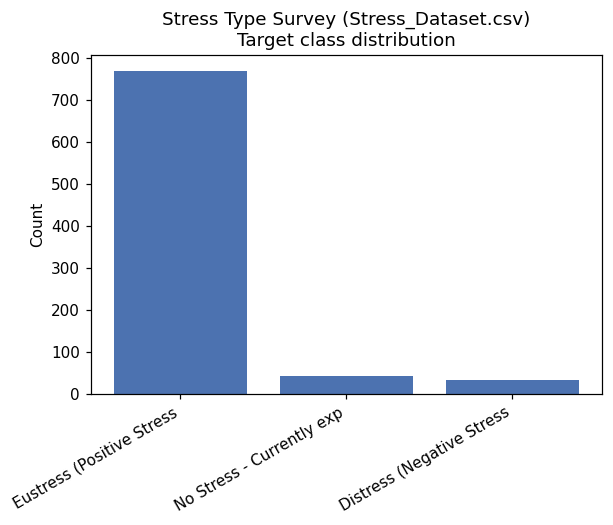

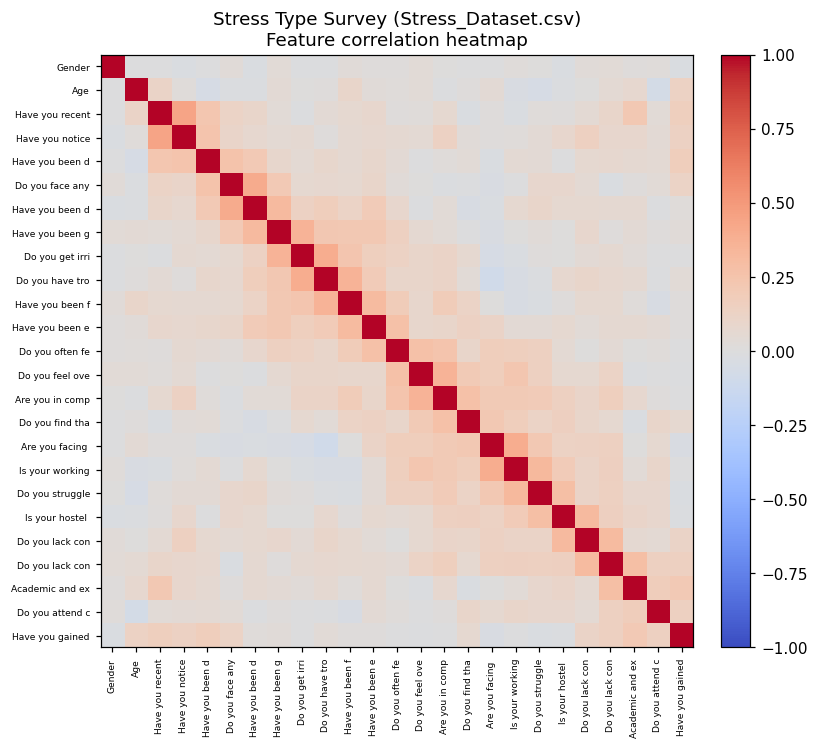

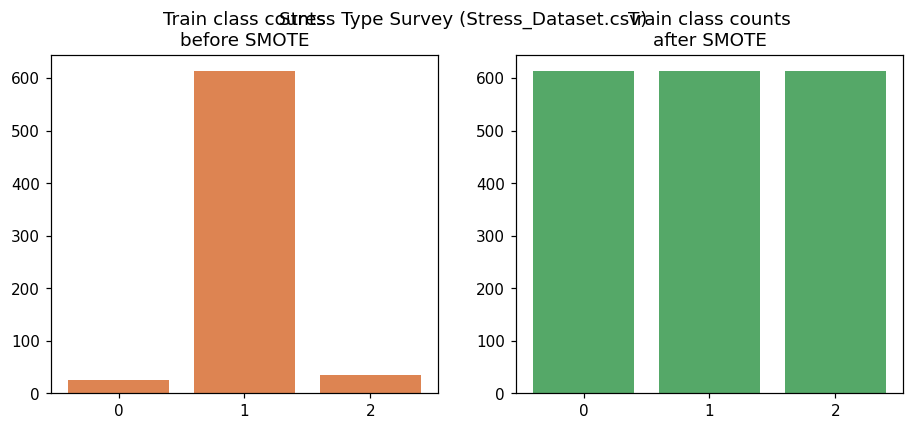

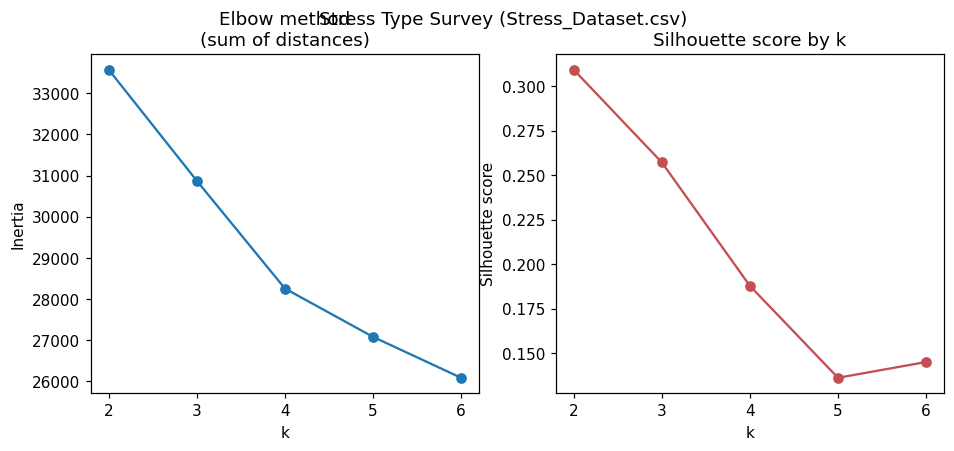

[dataset_a] chosen k (best silhouette) = 2  |  silhouette scores: {2: np.float64(0.30918656540827), 3: np.float64(0.25718365255030506), 4: np.float64(0.18787571488365412), 5: np.float64(0.13630892105635892), 6: np.float64(0.145158998339702)}


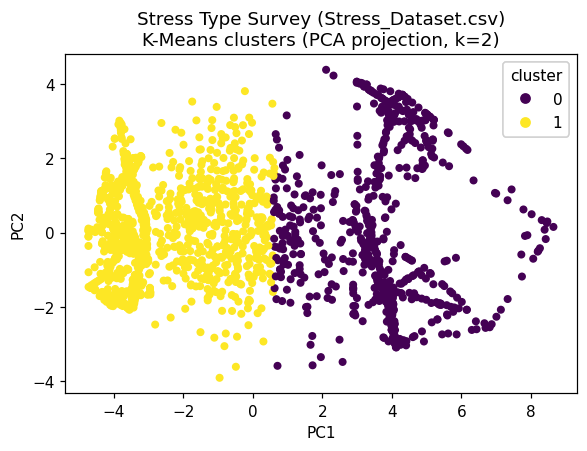


--- Stress Type Survey (Stress_Dataset.csv): Logistic Regression ---
                                                                                 precision    recall  f1-score   support

Distress (Negative Stress) - Stress that causes anxiety and impairs well-being.       1.00      1.00      1.00         3
   Eustress (Positive Stress) - Stress that motivates and enhances performance.       1.00      1.00      1.00        77
                       No Stress - Currently experiencing minimal to no stress.       1.00      1.00      1.00         5

                                                                       accuracy                           1.00        85
                                                                      macro avg       1.00      1.00      1.00        85
                                                                   weighted avg       1.00      1.00      1.00        85



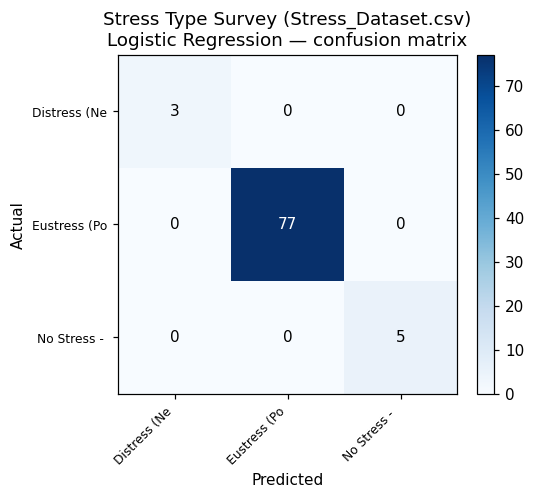

/usr/local/lib/python3.12/dist-packages/xgboost/core.py:553: UserWarning: [11:24:57] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



--- Stress Type Survey (Stress_Dataset.csv): XGBoost ---
                                                                                 precision    recall  f1-score   support

Distress (Negative Stress) - Stress that causes anxiety and impairs well-being.       1.00      0.67      0.80         3
   Eustress (Positive Stress) - Stress that motivates and enhances performance.       0.96      1.00      0.98        77
                       No Stress - Currently experiencing minimal to no stress.       1.00      0.60      0.75         5

                                                                       accuracy                           0.96        85
                                                                      macro avg       0.99      0.76      0.84        85
                                                                   weighted avg       0.97      0.96      0.96        85



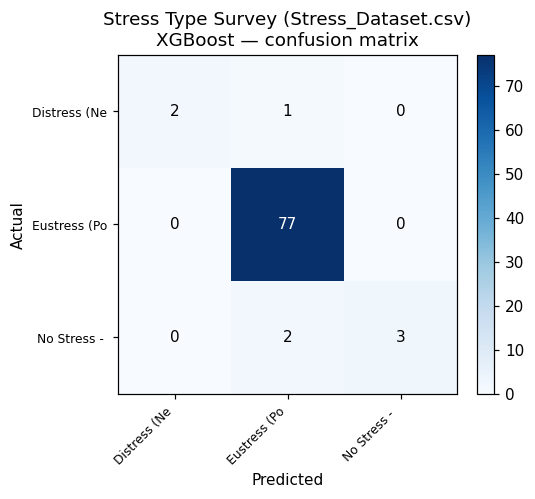

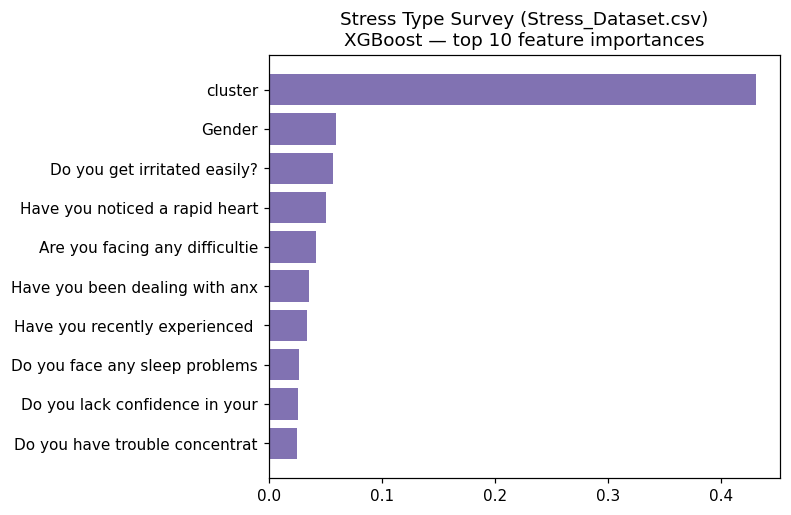

[dataset_a] epoch   1/80  train_loss=0.6342  val_loss=0.7437  val_acc=0.6190
[dataset_a] epoch  10/80  train_loss=0.0376  val_loss=0.2344  val_acc=0.9286
[dataset_a] epoch  20/80  train_loss=0.0128  val_loss=0.2892  val_acc=0.9286
[dataset_a] epoch  30/80  train_loss=0.0064  val_loss=0.2844  val_acc=0.9167
[dataset_a] epoch  40/80  train_loss=0.0083  val_loss=0.3049  val_acc=0.9167
[dataset_a] epoch  50/80  train_loss=0.0022  val_loss=0.3048  val_acc=0.9405
[dataset_a] epoch  60/80  train_loss=0.0061  val_loss=0.3288  val_acc=0.9405
[dataset_a] epoch  70/80  train_loss=0.0024  val_loss=0.3019  val_acc=0.9405
[dataset_a] epoch  80/80  train_loss=0.0028  val_loss=0.3222  val_acc=0.9524


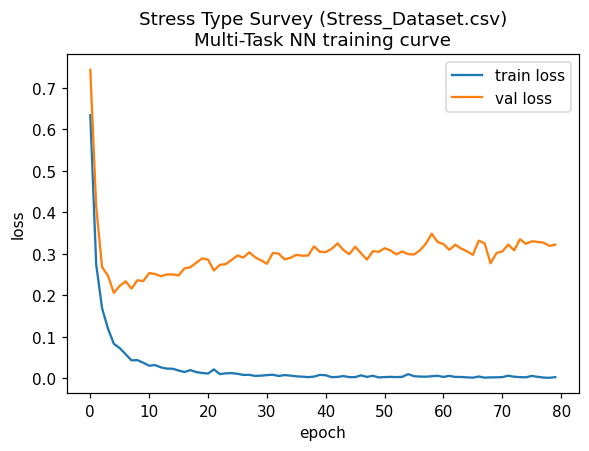


--- Stress Type Survey (Stress_Dataset.csv): Multi-Task NN ---
                                                                                 precision    recall  f1-score   support

Distress (Negative Stress) - Stress that causes anxiety and impairs well-being.       1.00      0.67      0.80         3
   Eustress (Positive Stress) - Stress that motivates and enhances performance.       0.99      1.00      0.99        77
                       No Stress - Currently experiencing minimal to no stress.       1.00      1.00      1.00         5

                                                                       accuracy                           0.99        85
                                                                      macro avg       1.00      0.89      0.93        85
                                                                   weighted avg       0.99      0.99      0.99        85



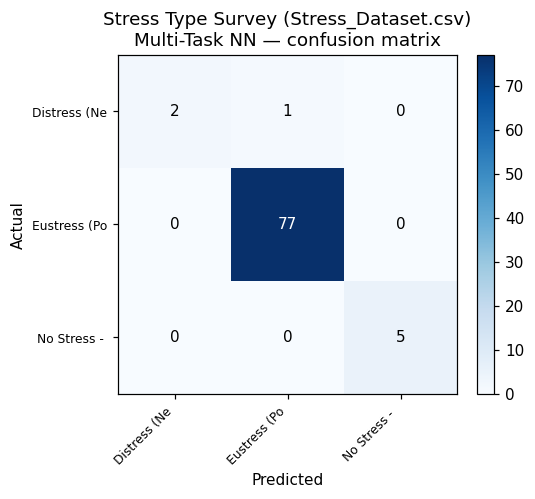


=== Stress Type Survey (Stress_Dataset.csv) — Model comparison ===


,Model,Training Accuracy,Test Accuracy,Test F1 (weighted),Test F1 (macro)
0,Logistic Regression,0.999457,1.000000,1.000000,1.000000
1,XGBoost,1.000000,0.964706,0.960925,0.843631
2,Multi-Task NN (GPU),1.000000,0.988235,0.987097,0.931183


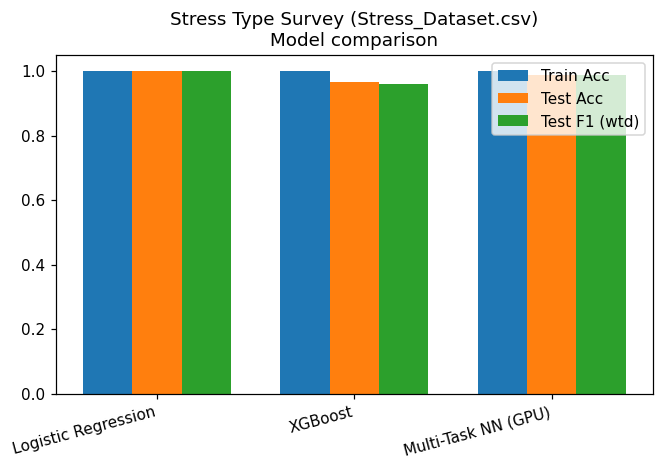

In [15]:
EXPERIMENTS = {}
EXPERIMENTS["dataset_a"] = run_experiment("dataset_a")


=== Stress Level Dataset (StressLevelDataset.csv) ===
Shape: (1100, 21)
Missing values total: 0


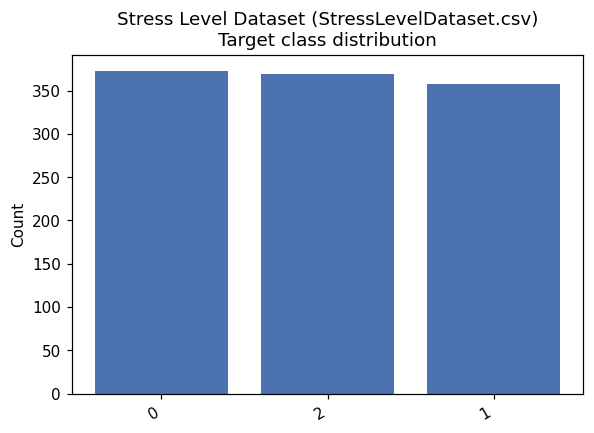

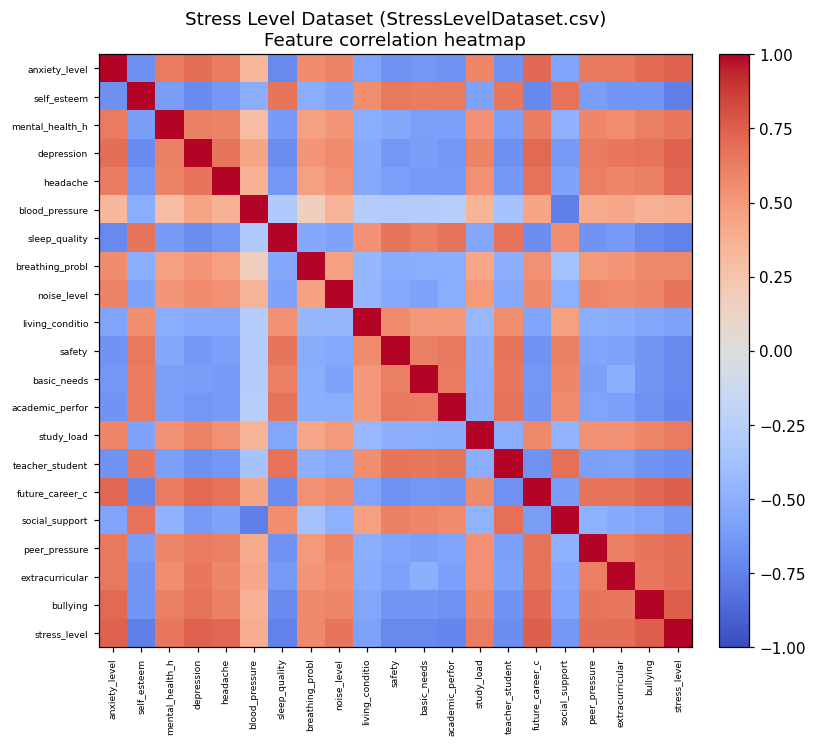

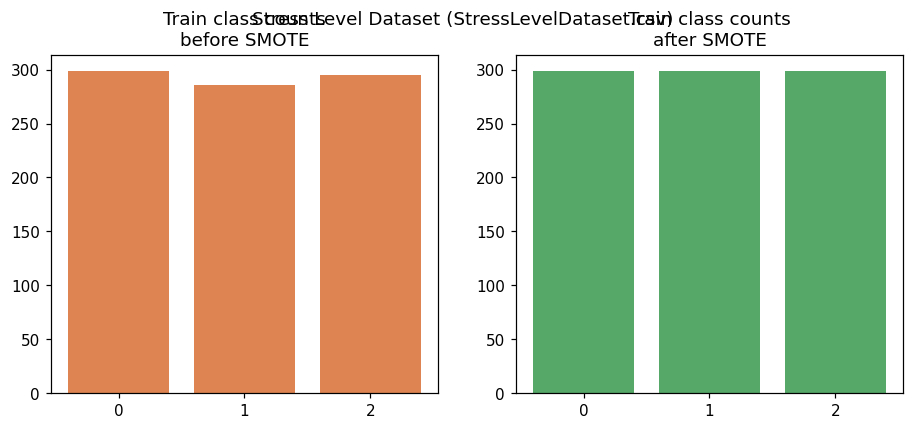

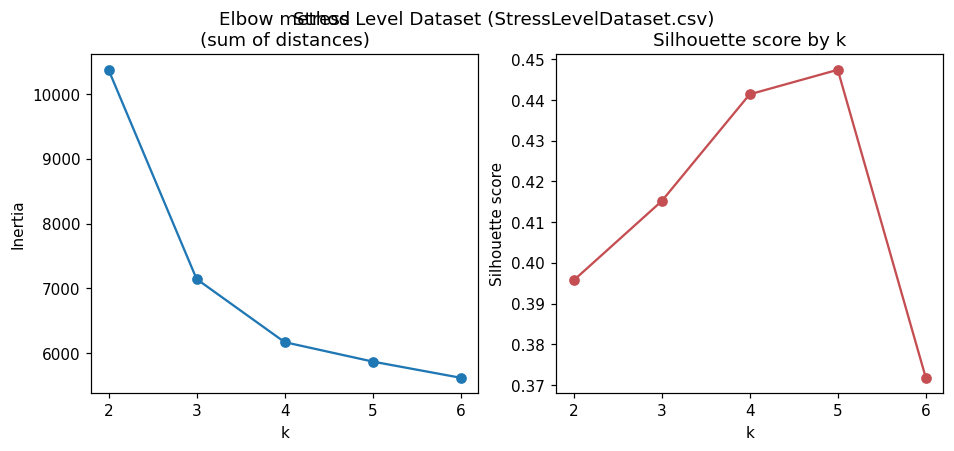

[dataset_b] chosen k (best silhouette) = 5  |  silhouette scores: {2: np.float64(0.3956794188690113), 3: np.float64(0.4151370101095264), 4: np.float64(0.4413722823991497), 5: np.float64(0.44738787397418045), 6: np.float64(0.3717983866420325)}


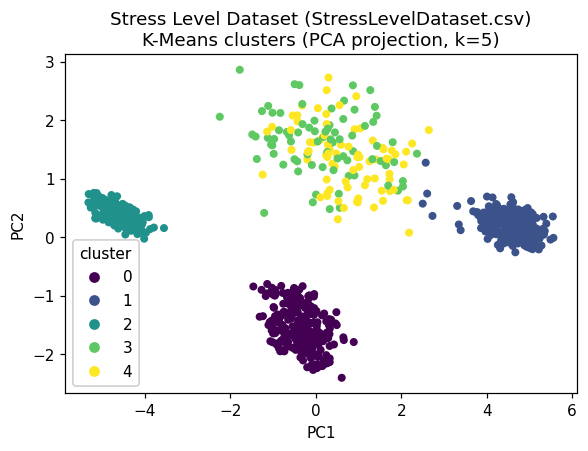


--- Stress Level Dataset (StressLevelDataset.csv): Logistic Regression ---
              precision    recall  f1-score   support

           0       0.87      0.89      0.88        37
           1       0.92      0.92      0.92        36
           2       0.92      0.89      0.90        37

    accuracy                           0.90       110
   macro avg       0.90      0.90      0.90       110
weighted avg       0.90      0.90      0.90       110



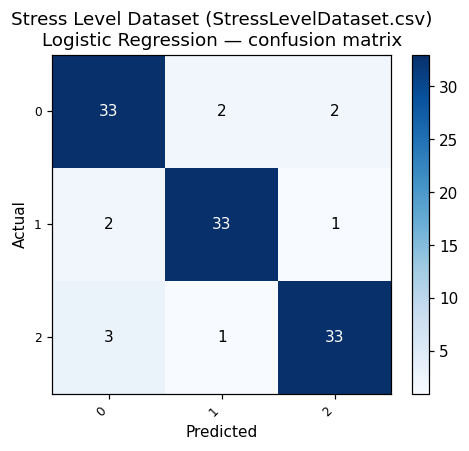


--- Stress Level Dataset (StressLevelDataset.csv): XGBoost ---
              precision    recall  f1-score   support

           0       0.89      0.89      0.89        37
           1       0.92      0.92      0.92        36
           2       0.89      0.89      0.89        37

    accuracy                           0.90       110
   macro avg       0.90      0.90      0.90       110
weighted avg       0.90      0.90      0.90       110



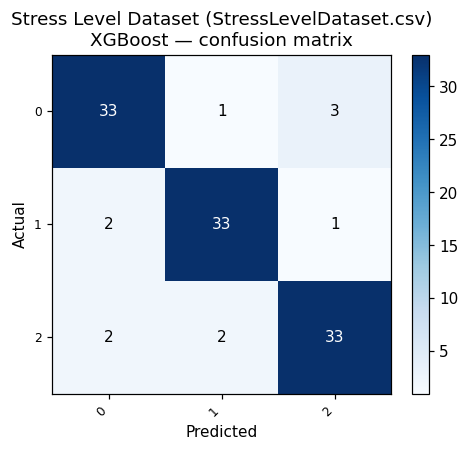

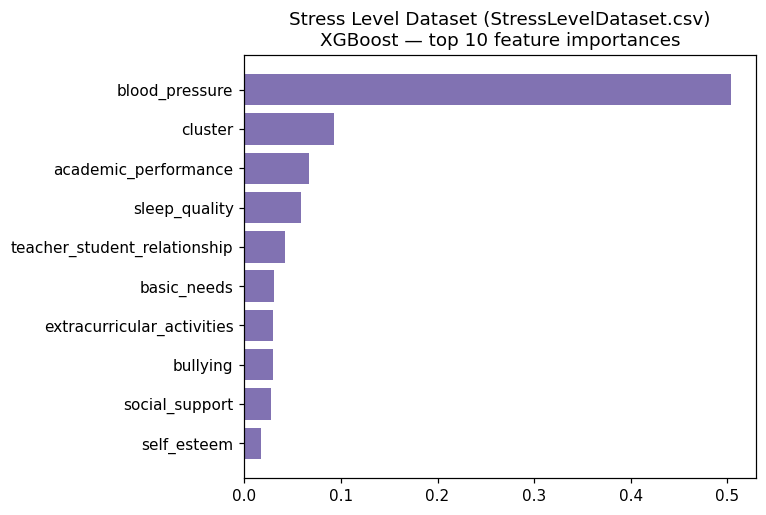

[dataset_b] epoch   1/80  train_loss=0.8538  val_loss=0.5732  val_acc=0.8545
[dataset_b] epoch  10/80  train_loss=0.1833  val_loss=0.2674  val_acc=0.8636
[dataset_b] epoch  20/80  train_loss=0.1189  val_loss=0.2830  val_acc=0.8273
[dataset_b] epoch  30/80  train_loss=0.0842  val_loss=0.3283  val_acc=0.8364
[dataset_b] epoch  40/80  train_loss=0.0555  val_loss=0.3764  val_acc=0.8455
[dataset_b] epoch  50/80  train_loss=0.0431  val_loss=0.4246  val_acc=0.8545
[dataset_b] epoch  60/80  train_loss=0.0284  val_loss=0.4610  val_acc=0.8455
[dataset_b] epoch  70/80  train_loss=0.0300  val_loss=0.4890  val_acc=0.8455
[dataset_b] epoch  80/80  train_loss=0.0254  val_loss=0.5412  val_acc=0.8273


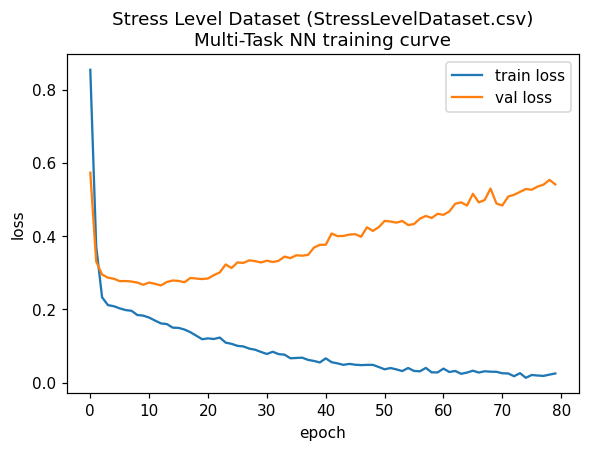


--- Stress Level Dataset (StressLevelDataset.csv): Multi-Task NN ---
              precision    recall  f1-score   support

           0       0.92      0.92      0.92        37
           1       0.97      0.92      0.94        36
           2       0.90      0.95      0.92        37

    accuracy                           0.93       110
   macro avg       0.93      0.93      0.93       110
weighted avg       0.93      0.93      0.93       110



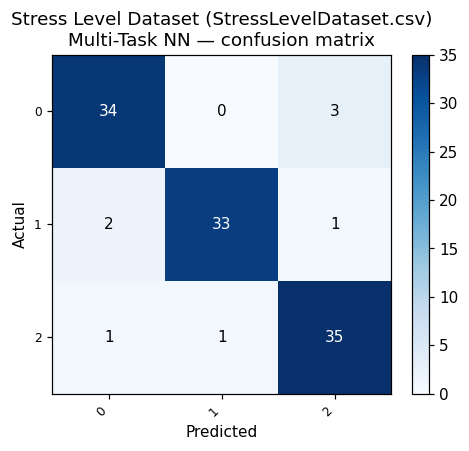


=== Stress Level Dataset (StressLevelDataset.csv) — Model comparison ===


,Model,Training Accuracy,Test Accuracy,Test F1 (weighted),Test F1 (macro)
0,Logistic Regression,0.908584,0.900000,0.900110,0.900259
1,XGBoost,1.000000,0.900000,0.900000,0.900150
2,Multi-Task NN (GPU),1.000000,0.927273,0.927471,0.927610


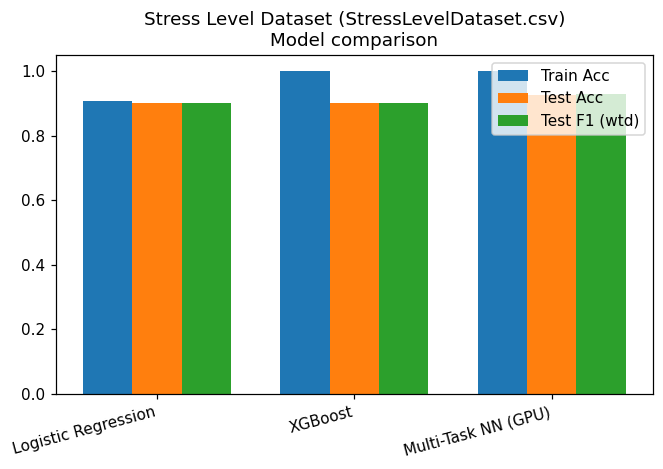

In [16]:
EXPERIMENTS["dataset_b"] = run_experiment("dataset_b")


## 12. Combined comparison across both datasets

=== Combined model performance across both datasets ===


,Dataset,Model,Training Accuracy,Test Accuracy,Test F1 (weighted),Test F1 (macro)
0,Stress Type Survey (Stress_Dataset.csv),Logistic Regression,0.999457,1.000000,1.000000,1.000000
1,Stress Type Survey (Stress_Dataset.csv),XGBoost,1.000000,0.964706,0.960925,0.843631
2,Stress Type Survey (Stress_Dataset.csv),Multi-Task NN (GPU),1.000000,0.988235,0.987097,0.931183
3,Stress Level Dataset (StressLevelDataset.csv),Logistic Regression,0.908584,0.900000,0.900110,0.900259
4,Stress Level Dataset (StressLevelDataset.csv),XGBoost,1.000000,0.900000,0.900000,0.900150
5,Stress Level Dataset (StressLevelDataset.csv),Multi-Task NN (GPU),1.000000,0.927273,0.927471,0.927610


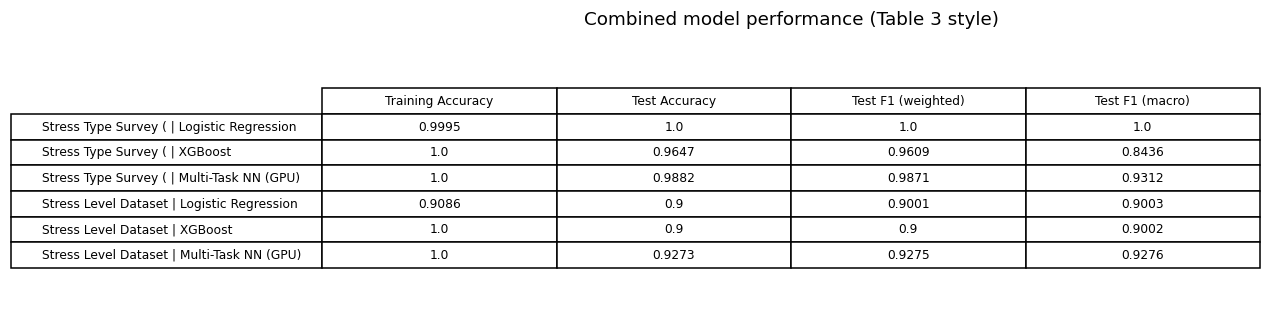

'/content/drive/MyDrive/stress_experiment_outputs/figures/combined_results_table.png'

In [17]:
combined_rows = []
for key, exp in EXPERIMENTS.items():
    for _, row in exp["results_df"].iterrows():
        combined_rows.append({"Dataset": exp["cfg"]["display_name"], **row.to_dict()})

combined_df = pd.DataFrame(combined_rows)
print("=== Combined model performance across both datasets ===")
display(combined_df)

combined_path = os.path.join(METRICS_DIR, "combined_results.csv")
combined_df.to_csv(combined_path, index=False)

# Render the same table as a matplotlib figure too, so it's saved alongside the other visuals
fig, ax = plt.subplots(figsize=(11, 0.5 + 0.4 * len(combined_df)))
ax.axis("off")
tbl = ax.table(cellText=np.round(combined_df.select_dtypes(include=[np.number]).values, 4),
               rowLabels=combined_df["Dataset"].str[:20] + " | " + combined_df["Model"],
               colLabels=combined_df.select_dtypes(include=[np.number]).columns,
               loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(8); tbl.scale(1, 1.4)
ax.set_title("Combined model performance (Table 3 style)", pad=20)
save_and_show(fig, "combined", "results_table")


## 13. Export: figures, models, and evaluation metrics

Everything has already been saved incrementally to `OUTPUT_DIR` as the notebook ran:
- `figures/` — every plot above, as PNG
- `metrics/` — per-dataset and combined results CSVs
- `models/` — every trained model, saved below

Run the next cell to save the models, then the final cell to zip everything and download it
(or just browse `OUTPUT_DIR` directly if you mounted Drive — it's already there).

In [18]:
import joblib

for dataset_key, exp in EXPERIMENTS.items():
    prep = exp["prep"]
    prefix = os.path.join(MODELS_DIR, dataset_key)

    joblib.dump(prep["scaler"], f"{prefix}_scaler.joblib")
    joblib.dump(prep["kmeans"], f"{prefix}_kmeans.joblib")
    if prep["label_encoder"] is not None:
        joblib.dump(prep["label_encoder"], f"{prefix}_label_encoder.joblib")

    joblib.dump(prep["models"]["logreg"], f"{prefix}_logreg.joblib")
    prep["models"]["xgboost"].save_model(f"{prefix}_xgboost.json")

    torch.save(prep["models"]["multitask_nn"].state_dict(), f"{prefix}_multitask_nn.pt")
    with open(f"{prefix}_multitask_nn_arch.json", "w") as f:
        _json.dump(prep["nn_arch"], f)

    print(f"Saved all {dataset_key} models to {MODELS_DIR}")

print("\nAll figures saved:", len(FIGURE_LOG), "files in", FIGURES_DIR)
print("All metrics saved in", METRICS_DIR)


Saved all dataset_a models to /content/drive/MyDrive/stress_experiment_outputs/models
Saved all dataset_b models to /content/drive/MyDrive/stress_experiment_outputs/models

All figures saved: 23 files in /content/drive/MyDrive/stress_experiment_outputs/figures
All metrics saved in /content/drive/MyDrive/stress_experiment_outputs/metrics


In [19]:
import shutil
from google.colab import files as colab_files

ARCHIVE_BASENAME = "/content/stress_experiment_outputs"
archive_path = shutil.make_archive(ARCHIVE_BASENAME, "zip", OUTPUT_DIR)
print("Created archive:", archive_path)

# Triggers a browser download of the zip (figures + models + metrics)
colab_files.download(archive_path)


Created archive: /content/stress_experiment_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Reloading a saved model later (reference snippet)

```python
import joblib, json, torch

scaler = joblib.load(f"{MODELS_DIR}/dataset_a_scaler.joblib")
kmeans = joblib.load(f"{MODELS_DIR}/dataset_a_kmeans.joblib")
logreg = joblib.load(f"{MODELS_DIR}/dataset_a_logreg.joblib")

from xgboost import XGBClassifier
xgb_clf = XGBClassifier()
xgb_clf.load_model(f"{MODELS_DIR}/dataset_a_xgboost.json")

with open(f"{MODELS_DIR}/dataset_a_multitask_nn_arch.json") as f:
    arch = json.load(f)
nn_model = MultiTaskMLP(**arch)
nn_model.load_state_dict(torch.load(f"{MODELS_DIR}/dataset_a_multitask_nn.pt"))
nn_model.eval()
```
